# When to fly a thermal camera: surface temperatures from real weather

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/thermal_timing_brno_en.ipynb)

**OpenSkyLab · notebook for the visual** [When to fly a thermal camera](https://openskylab.space/edu_viz_thermal_timing.html) · [česká verze](thermal_timing_brno_cs.ipynb)

The visual shows how water, meadow, asphalt, forest and photovoltaics warm up and cool down during the day, and when two surfaces merge in a thermal image. Here you drive the same kind of model (surface energy balance with heat conduction into the ground) with real hourly weather from the last months in Brno and look for the best flight time for a given task.

**Goal:** compute the daily course of surface temperatures from real radiation, temperature, humidity, cloud cover and wind, find the times when two surfaces cross over in temperature, compare a clear and an overcast day, show the effect of wind and of the emissivity set in the camera, and find the hours suitable for inspecting photovoltaics.

**Data:** hourly air temperature and humidity, global radiation on a horizontal and a tilted surface, cloud cover, wind at 10 m and soil surface temperature from Open-Meteo for the centre of Brno, whatever the service returns for the last 92 days, usually two to three months (weather model, not an on-site measurement); thermal properties of materials from the literature.

**Tasks:** six. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and real weather

Open-Meteo: SSLError – retrying


weather 20 Aug to 31 Oct 2026, 1751 hours
sunniest day 2026-09-06 (5.3 kWh/m²), most overcast 2026-09-11 (0.7 kWh/m²)


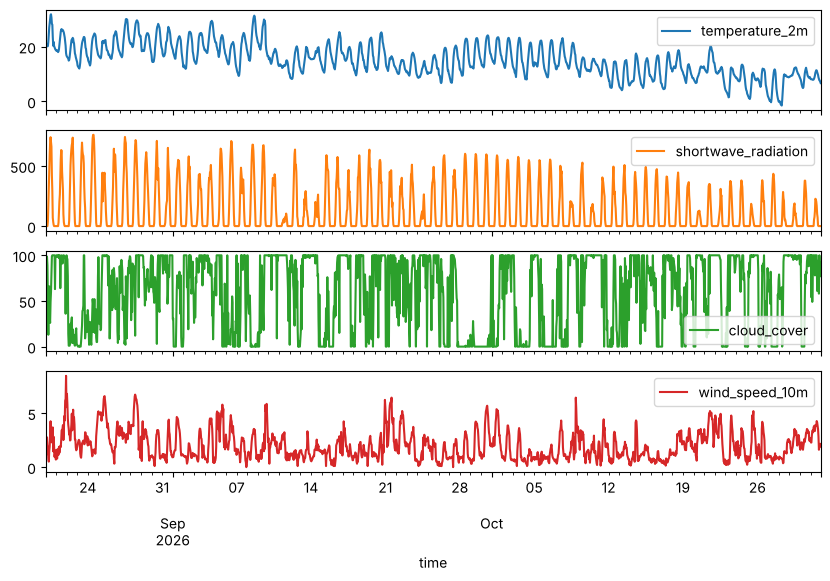

In [1]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

LAT, LON = 49.195, 16.608     # ◀ parameter: site (centre of Brno)
TILT, AZ = 35, 0              # ◀ parameter: tilt and azimuth of the PV panels (°; azimuth 0 = south, −90 = east, 90 = west)

def weather(lat, lon, tilt, az):
    j = open_meteo({"latitude": lat, "longitude": lon, "past_days": 92, "forecast_days": 1,
                    "hourly": "temperature_2m,relative_humidity_2m,shortwave_radiation,global_tilted_irradiance,cloud_cover,wind_speed_10m,soil_temperature_0cm",
                    "tilt": tilt, "azimuth": az, "timezone": "Europe/Prague", "wind_speed_unit": "ms"})
    w = pd.DataFrame(j["hourly"]); w["time"] = pd.to_datetime(w.time)
    return w.set_index("time").dropna()

w = weather(LAT, LON, TILT, AZ)
days = w.shortwave_radiation.resample("D").sum() / 1000           # kWh/m² per day
days = days.iloc[14:-1]                                          # the first 14 days are model spin-up, the last day is incomplete
SUNNY, CLOUDY = days.idxmax().date(), days.idxmin().date()
print(f"weather {w.index[0]:%d %b} to {w.index[-1]:%d %b %Y}, {len(w)} hours")
print(f"sunniest day {SUNNY} ({days.max():.1f} kWh/m²), most overcast {CLOUDY} ({days.min():.1f} kWh/m²)")
w[["temperature_2m", "shortwave_radiation", "cloud_cover", "wind_speed_10m"]].plot(subplots=True, figsize=(10, 6), legend=True); plt.show()

## 2. The surface model and one clear day

For every surface the energy balance **Rn = H + LE + G** is solved every minute:

- Rn: absorbed solar radiation (1 − albedo) · S plus the long-wave balance ε (L↓ − σ T⁴). The sky L↓ comes from air temperature and humidity (Brutsaert 1975) and from cloud cover (Crawford and Duchon 1999).
- H: sensible heat to the air h · (T − Tₐ), h = 5.7 + 3.8 U, where U is the wind at 2 m (from the 10 m wind by a logarithmic profile, ×0.75).
- LE: evaporation ρ L (q*(T) − qₐ) / (rₐ + r_s); the stomatal resistance r_s is 70 s/m for the meadow and 100 s/m for the forest, water evaporates freely, asphalt and the panel not at all.
- G: heat into the ground. Asphalt and soil have 12 layers down to 1 m, the pond is a mixed water layer of 1 m, the forest canopy and the PV panel are a thin layer with no conduction into the ground.

Solar radiation, temperature, humidity, cloud cover and wind are real hourly values from Open-Meteo. The model runs from the start of the period; the first 14 days are spin-up.

water × meadow: crossover at 07:58
water × meadow: crossover at 17:18


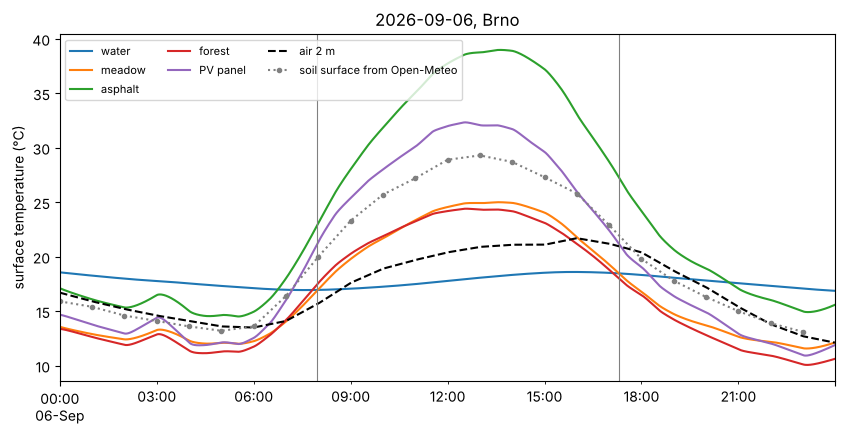

                     water  meadow  asphalt  forest  PV panel
2026-09-06 02:00:00   17.9    12.7     15.7    12.3      13.6
2026-09-06 05:00:00   17.2    12.1     14.6    11.4      12.1
2026-09-06 08:00:00   17.0    18.5     25.6    19.0      23.6
2026-09-06 11:00:00   17.6    24.0     36.5    23.8      31.2
2026-09-06 13:00:00   18.2    25.0     38.9    24.3      32.0
2026-09-06 16:00:00   18.6    20.6     30.9    20.1      24.2
2026-09-06 19:00:00   17.9    14.2     19.7    13.5      15.6
2026-09-06 22:00:00   17.2    11.9     15.5    10.5      11.5


In [2]:
SIG = 5.670e-8
# albedo, emissivity, thermal conductivity k (W/m/K), volumetric heat capacity C (J/m³/K), stomatal resistance r_s (s/m; inf = no evaporation),
# node = heat capacity of a single layer (J/m²/K) for surfaces with no conduction into the ground, rough = multiple of heat transfer (roughness), sides = cooled from both sides
SURF = {
    "water":     dict(alb=0.06, eps=0.99, k=0.0,  C=0.0,    rs=0.0,    node=4.18e6 * 1.0),
    "meadow":    dict(alb=0.20, eps=0.98, k=1.2,  C=2.5e6,  rs=70.0),
    "asphalt":   dict(alb=0.08, eps=0.95, k=0.75, C=1.94e6, rs=np.inf),
    "forest":    dict(alb=0.12, eps=0.98, k=0.0,  C=0.0,    rs=100.0,  node=3.0e4, rough=3),
    "PV panel":  dict(alb=0.30, eps=0.85, k=0.0,  C=0.0,    rs=np.inf, node=1.5e4, sides=2, tilted=1),
}

def qsat(T):
    """Saturation specific humidity (kg/kg) at temperature T in kelvin (Magnus, 1013 hPa)."""
    return 0.622 * 610.94 * np.exp(17.625 * (T - 273.15) / (T - 30.11)) / 101325

def simulate(w, surf=SURF, wind_factor=1.0, dt=60, nl=12, depth=1.0):
    t = (w.index - w.index[0]).total_seconds().values
    ts = np.arange(0, t[-1], dt)
    Ta = np.interp(ts, t, w.temperature_2m.values) + 273.15
    RH = np.interp(ts, t, w.relative_humidity_2m.values) / 100
    S = np.interp(ts, t - 1800, w.shortwave_radiation.values)          # radiation is the mean over the preceding hour
    S_tilt = np.interp(ts, t - 1800, w.global_tilted_irradiance.values)
    cc = np.interp(ts, t, w.cloud_cover.values) / 100
    U = np.maximum(np.interp(ts, t, w.wind_speed_10m.values) * 0.75 * wind_factor, 0.3)
    e = RH * 610.94 * np.exp(17.625 * (Ta - 273.15) / (Ta - 30.11))
    eps_sky = 1.24 * (e / 100 / Ta) ** (1 / 7) * (1 - cc) + cc
    Ld = eps_sky * SIG * Ta ** 4
    qa = RH * qsat(Ta)
    names = list(surf)
    p = {k: np.array([surf[n].get(k, d) for n in names], float) for k, d in
         [("alb", 0), ("eps", 1), ("k", 0), ("C", 0), ("rs", np.inf), ("node", 0), ("rough", 1), ("sides", 1), ("tilted", 0)]}
    r = 1.0
    while 0.01 * (r ** nl - 1) / (r - 1 + 1e-12) < depth: r += 0.001
    dz = 0.01 * r ** np.arange(nl)                                      # layers from 1 cm, thicker with depth
    single = p["node"] > 0
    cap = np.outer(p["C"], dz); cap[single, 0] = p["node"][single]; cap[single, 1:] = 1
    kk = np.outer(p["k"], np.ones(nl - 1)) / ((dz[1:] + dz[:-1]) / 2)
    T = np.full((len(names), nl), Ta[: int(3 * 86400 / dt)].mean())
    out = np.empty((len(ts), len(names)))
    rho, cp, L = 1.2, 1005, 2.45e6
    for i in range(len(ts)):
        Ts = T[:, 0]
        h = (5.7 + 3.8 * U[i]) * p["rough"]
        sw = np.where(p["tilted"] > 0, S_tilt[i], S[i])
        Rn = (1 - p["alb"]) * sw + p["eps"] * (Ld[i] - SIG * Ts ** 4) + (p["sides"] - 1) * p["eps"] * SIG * (Ta[i] ** 4 - Ts ** 4)
        H = h * p["sides"] * (Ts - Ta[i])
        LE = np.where(np.isinf(p["rs"]), 0.0, rho * L * (qsat(Ts) - qa[i]) / (rho * cp / h + np.where(np.isinf(p["rs"]), 0, p["rs"])))
        flux = kk * (T[:, :-1] - T[:, 1:])
        dT = np.zeros_like(T)
        dT[:, 0] = Rn - H - LE - flux[:, 0]
        dT[:, 1:-1] = flux[:, :-1] - flux[:, 1:]
        dT[:, -1] = flux[:, -1]
        T += dt * dT / cap
        out[i] = T[:, 0]
    idx = w.index[0] + pd.to_timedelta(ts, "s")
    res = pd.DataFrame(out - 273.15, index=idx, columns=names)
    res.attrs["Ld"] = pd.Series(Ld, index=idx); res.attrs["Ta"] = pd.Series(Ta - 273.15, index=idx)
    return res

def crossings(a, b):
    """Times at which the difference a − b changes sign (linear interpolation between minutes)."""
    d = (a - b).values; i = np.where(np.sign(d[:-1]) * np.sign(d[1:]) < 0)[0]
    return [a.index[k] + (a.index[k + 1] - a.index[k]) * (d[k] / (d[k] - d[k + 1])) for k in i]

T = simulate(w)
DAY = SUNNY                   # ◀ parameter: day, e.g. "2026-09-10"; the default is the sunniest day
A, B = "water", "meadow"      # ◀ parameter: pair of surfaces
d = T.loc[str(DAY)]
ax = d.plot(figsize=(10, 4.5))
T.attrs["Ta"].loc[str(DAY)].plot(ax=ax, color="k", ls="--", label="air 2 m")
w.soil_temperature_0cm.loc[str(DAY)].plot(ax=ax, color="gray", ls=":", marker=".", label="soil surface from Open-Meteo")
for c in crossings(d[A], d[B]):
    ax.axvline(c, color="gray", lw=0.8); print(f"{A} × {B}: crossover at {c:%H:%M}")
ax.set_ylabel("surface temperature (°C)"); ax.set_xlabel(""); ax.set_title(f"{DAY}, Brno"); ax.legend(ncol=3, fontsize=8); plt.show()
print(d.resample("h").mean().iloc[[2, 5, 8, 11, 13, 16, 19, 22]].round(1))

> **✏️ Task 1.** Read off the times of both crossovers of water and meadow. Why is water warmer than the meadow at night and colder at noon? Compare the modelled meadow with the soil surface temperature from Open-Meteo (dotted): where do they differ most and why might that be (it is a model too, not a measurement)? Try the pair asphalt × forest.

*Your answer:* 

## 3. Clear or overcast?

We compare the sunniest and the most overcast day in the downloaded data. The amplitude is the difference between the daily maximum and minimum of surface temperature.

2026-09-06: radiation 5.3 kWh/m², cloud cover 17 %, wind 2.8 m/s


2026-09-11: radiation 0.7 kWh/m², cloud cover 91 %, wind 1.8 m/s
          2026-09-06: amplitude  2026-09-11: amplitude
water                       1.7                    2.9
meadow                     13.4                    5.8
asphalt                    24.5                    8.5
forest                     14.3                    7.5
PV panel                   21.4                    9.3
{'2026-09-06: water − meadow at 3:00': 4.5, '2026-09-11: water − meadow at 3:00': 3.8}


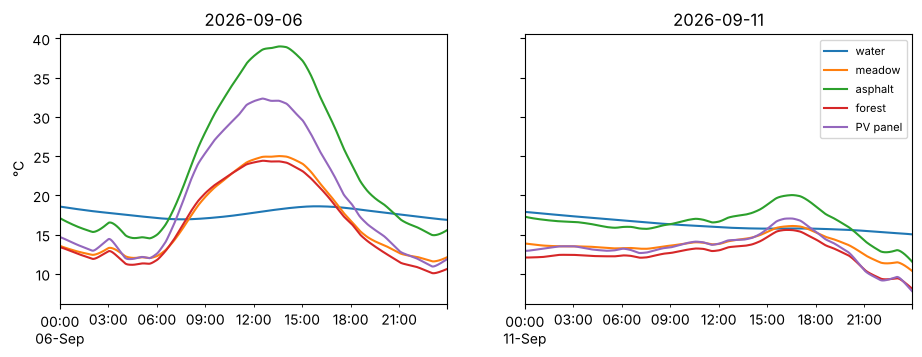

In [3]:
DAYS = [SUNNY, CLOUDY]        # ◀ parameter: days to compare (you can add a third one, e.g. "2026-09-20")
rows = {}
for day in DAYS:
    d = T.loc[str(day)]
    rows[f"{day}: amplitude"] = d.max() - d.min()
    rows[f"{day}: water − meadow at 3:00"] = d.between_time("02:55", "03:05").mean()["water"] - d.between_time("02:55", "03:05").mean()["meadow"]
    print(f"{day}: radiation {days.loc[pd.Timestamp(day)]:.1f} kWh/m², cloud cover {w.cloud_cover.loc[str(day)].mean():.0f} %, wind {w.wind_speed_10m.loc[str(day)].mean():.1f} m/s")
print(pd.DataFrame({k: v for k, v in rows.items() if "amplitude" in k}).round(1))
print({k: round(float(v), 1) for k, v in rows.items() if "meadow" in k})
fig, ax = plt.subplots(1, len(DAYS), figsize=(11, 3.5), sharey=True)
for a, day in zip(np.atleast_1d(ax), DAYS):
    T.loc[str(day)].plot(ax=a, legend=False); a.set_title(str(day))
np.atleast_1d(ax)[0].set_ylabel("°C"); np.atleast_1d(ax)[-1].legend(fontsize=8); plt.show()

> **✏️ Task 2.** By how much did the amplitude of asphalt and water shrink on the overcast day? What happened to the water − meadow difference at night? Explain the role of solar radiation during the day and of long-wave radiation from clouds at night.

*Your answer:* 

## 4. Contrast calendar: when to fly

For every day and hour we compute the temperature difference of a pair of surfaces. White areas are crossovers, when the surfaces merge in a thermal image.

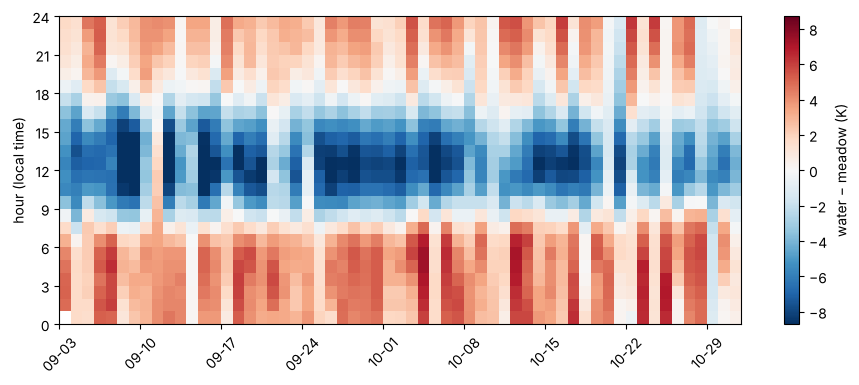

share of days with |water − meadow| ≥ 3 K, by hour (%):
hour    0     1     2     3     4     5     6     7    8     9     10    11    12    13    14    15    16   17   18    19    20    21    22    23
%     54.0  59.0  61.0  66.0  69.0  69.0  56.0  24.0  7.0  49.0  80.0  88.0  86.0  83.0  83.0  76.0  34.0  7.0  3.0  14.0  25.0  36.0  44.0  51.0


In [4]:
A, B = "water", "meadow"      # ◀ parameter: pair of surfaces
MIN_DT = 3                    # ◀ parameter: contrast you can still reliably tell apart in a thermal image (K)
h = (T[A] - T[B]).iloc[14 * 1440:].resample("h").mean()
grid = h.to_frame("d").assign(day=h.index.date, hour=h.index.hour).pivot(index="hour", columns="day", values="d")
lim = np.nanpercentile(np.abs(grid.values), 98)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.pcolormesh(range(grid.shape[1] + 1), range(25), grid.values, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_yticks(range(0, 25, 3)); ax.set_ylabel("hour (local time)")
ax.set_xticks(range(0, grid.shape[1], 7)); ax.set_xticklabels([str(c)[5:] for c in grid.columns[::7]], rotation=45)
plt.colorbar(im, label=f"{A} − {B} (K)"); plt.show()
ok = (grid.abs() >= MIN_DT).mean(axis=1) * 100
print(f"share of days with |{A} − {B}| ≥ {MIN_DT} K, by hour (%):"); print(ok.round(0).to_frame("%").T.to_string())

> **✏️ Task 3.** In which hours is the contrast between water and meadow reliably large, and in which do the surfaces merge? How do the crossovers shift from summer to autumn and why? You are looking for wet spots in a meadow (pair meadow × water): when would you fly and why rather in the morning than at noon?

*Your answer:* 

## 5. Wind

We compute the same weather again with weaker and stronger wind (we multiply the wind). Everything else stays real.

In [5]:
FACTORS = [0.5, 1, 2, 4]      # ◀ parameter: multiples of the real wind
DAY_W = SUNNY                 # ◀ parameter: day
tab = {}
for f in FACTORS:
    d = simulate(w, wind_factor=f).loc[str(DAY_W)]
    tab[f"wind ×{f}"] = {"asphalt max": d["asphalt"].max(), "meadow min": d["meadow"].min(), "asphalt − meadow at 13:00": (d["asphalt"] - d["meadow"]).between_time("12:55", "13:05").mean()}
print(f"{DAY_W}: real wind at 10 m averaged {w.wind_speed_10m.loc[str(DAY_W)].mean():.1f} m/s")
pd.DataFrame(tab).round(1)

2026-09-06: real wind at 10 m averaged 2.8 m/s


,wind ×0.5,wind ×1,wind ×2,wind ×4
asphalt max,43.4,39.0,33.9,29.3
meadow min,11.9,11.6,11.3,11.3
asphalt − meadow at 13:00,16.5,13.8,10.3,6.8


> **✏️ Task 4.** How do the noon maximum of asphalt, the morning minimum of the meadow and the asphalt − meadow contrast change with stronger wind? Why does wind reduce contrasts in a thermal image? What wind limit would you recommend for a thermal flight?

*Your answer:* 

## 6. Emissivity in the camera and photovoltaics

The camera measures the exitance W = ε σ T⁴ + (1 − ε) σ T_refl⁴, where the second term is the reflected surroundings. It computes temperature using the emissivity ε_c and the reflected temperature T_refl set in the camera. Simplification: we compute over the whole spectrum, not only the 8–14 µm band, and take the reflected surroundings to be the sky.

For inspecting PV plants an irradiance of at least 600 W/m² on the panel is recommended (IEA PVPS). The irradiance of the tilted surface comes from Open-Meteo.

In [6]:
EPS_CAM = 1.00                # ◀ parameter: emissivity set in the camera (try 0.95 and 0.85)
T_REFL = 20.0                 # ◀ parameter: reflected temperature set in the camera (°C)
HOURS = ["05:00", "13:00"]    # ◀ parameter: times of the images
DAY_E = SUNNY                 # ◀ parameter: day
eps = pd.Series({n: v["eps"] for n, v in SURF.items()})
rows = {}
for hh in HOURS:
    tt = pd.Timestamp(f"{DAY_E} {hh}")
    Tk = T.loc[tt] + 273.15; Ld = T.attrs["Ld"].loc[tt]
    W = eps * SIG * Tk ** 4 + (1 - eps) * Ld
    Trad = ((W - (1 - EPS_CAM) * SIG * (T_REFL + 273.15) ** 4) / (EPS_CAM * SIG)) ** 0.25 - 273.15
    rows[f"{hh} true"] = T.loc[tt]; rows[f"{hh} camera"] = Trad; rows[f"{hh} error"] = Trad - T.loc[tt]
print(f"{DAY_E}, emissivity in the camera {EPS_CAM}, reflected temperature {T_REFL} °C")
print(pd.DataFrame(rows).round(1))

THRESH = 600                  # ◀ parameter: minimum panel irradiance for PV inspection (W/m²)
g = w.global_tilted_irradiance
ok = (g >= THRESH).groupby([g.index.to_period("M").rename("month"), g.index.hour.rename("hour")]).sum().unstack(fill_value=0)
print(f"\nNumber of hours with panel irradiance (tilt {TILT}°, azimuth {AZ}°) ≥ {THRESH} W/m² by month and hour:")
print(ok.loc[:, ok.sum() > 0].to_string())

2026-09-06, emissivity in the camera 1.0, reflected temperature 20.0 °C
          05:00 true  05:00 camera  05:00 error  13:00 true  13:00 camera  \
water           17.3          17.2         -0.1        18.1          18.0   
meadow          12.1          11.9         -0.2        24.9          24.6   
asphalt         14.6          14.1         -0.6        38.7          37.4   
forest          11.3          11.1         -0.2        24.3          24.0   
PV panel        12.1          10.8         -1.3        32.1          28.7   

          13:00 error  
water            -0.1  
meadow           -0.3  
asphalt          -1.4  
forest           -0.3  
PV panel         -3.4  

Number of hours with panel irradiance (tilt 35°, azimuth 0°) ≥ 600 W/m² by month and hour:
hour     10  11  12  13  14  15
month                          
2026-08   7  10   9  11   7   3
2026-09   8  13  16  12  12   4
2026-10   8  14  13  11   9   0


> **✏️ Task 5.** With emissivity 1.00 in the camera: which surface differs most from its true temperature and why does the PV panel look colder than it is? Set 0.95 and then 0.85: which surface is now right and which are not? Why is the error at night different from the one at noon (think of the reflected sky)?

*Your answer:* 

> **✏️ Task 6.** In which months and hours was the panel irradiance at least 600 W/m²? In step 1 change the tilt to 60° and the azimuth to −90° (east) and run the cells again: how does the inspection window shift? Why is the contrast of a faulty or disconnected module small in weak sunlight?

*Your answer:* 

> **✏️ Extension (optional).** Classmates may have the notebook for another site (Suchdol, Brno, Hluboká nad Vltavou). Compare the amplitude of asphalt and meadow temperature and the crossover time for the same date. Do they differ more because of that day's weather or because of the site?

*Your answer:* 

---
### Data sources and references

- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744 (clear-sky long-wave radiation).
- Crawford, T. M., Duchon, C. E. (1999). An improved parameterization for estimating effective atmospheric emissivity. *Journal of Applied Meteorology* 38, 474–480 (effect of cloud cover).
- Oke, T. R. (1987). *Boundary Layer Climates*, 2nd ed. Routledge (thermal conductivity and heat capacity of asphalt and soil, albedos).
- Maes, W. H. (2025). Practical guidelines for performing UAV mapping flights with snapshot sensors. *Remote Sensing* 17(4), 606. https://doi.org/10.3390/rs17040606 (planning mapping flights, thermal included).
- IEA PVPS Task 13 (2018). *Review on Infrared and Electroluminescence Imaging for PV Field Applications*, Report IEA-PVPS T13-10:2018 (glass emissivity 0.85, irradiance ≥ 600 W/m²).
- Convective heat transfer h = 5.7 + 3.8 U (McAdams), saturation vapour pressure by the Magnus formula (WMO-No. 8, 2018).

### How to cite

OpenSkyLab (2026). When to fly a thermal camera: surface temperatures from real weather [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/thermal_timing_brno_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*